In [4]:
import pandas as pd
import numpy as np
import re
import ast
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("anime_data_table.csv")

# Display basic information
print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

df.head()

Dataset loaded successfully!
Shape: (931, 55)

Column names:
['anime_id', 'mal_id', 'title', 'english_title', 'japanese_title', 'user_preferred_title', 'type', 'episodes', 'duration', 'status', 'source', 'season', 'season_year', 'studios', 'main_studios', 'genres', 'tags', 'rating', 'score', 'mean_score', 'scored_by', 'rank', 'popularity', 'popularity_rank', 'members', 'favorites', 'watching', 'completed', 'on_hold', 'dropped', 'plan_to_watch', 'start_date', 'end_date', 'broadcast_day', 'broadcast_time', 'synopsis', 'country_of_origin', 'is_licensed', 'hashtag', 'cover_image_large', 'cover_image_color', 'banner_image', 'trailer_site', 'trailer_id', 'main_characters', 'main_staff', 'streaming_sites', 'is_adult', 'synonyms', 'site_url', 'updated_at', 'next_airing_episode_at', 'next_episode_number', 'collected_at', 'data_source']


,anime_id,mal_id,title,english_title,japanese_title,user_preferred_title,type,episodes,duration,status,...,main_staff,streaming_sites,is_adult,synonyms,site_url,updated_at,next_airing_episode_at,next_episode_number,collected_at,data_source
0,176496,58567.0,Ore dake Level Up na Ken: Season 2 - Arise fro...,Solo Leveling Season 2 -Arise from the Shadow-,俺だけレベルアップな件 Season 2 -Arise from the Shadow-,Ore dake Level Up na Ken: Season 2 - Arise fro...,TV,13.0,24.0,FINISHED,...,Chu-Gong (Original Story);Hyeon-Gun (Original ...,Twitter;Twitter;Official Site;Crunchyroll;TikT...,False,Na Honjaman Level Up 2;나 혼자만 레벨업 2;俺だけレベルアップな件...,https://anilist.co/anime/176496,1792742458,0,0,2026-10-23T08:55:15.003352+00:00,anilist
1,177709,58939.0,SAKAMOTO DAYS,SAKAMOTO DAYS,SAKAMOTO DAYS,SAKAMOTO DAYS,ONA,11.0,24.0,FINISHED,...,Yuuto Suzuki (Original Creator);Masaki Watana...,Twitter;Official Site;Netflix,False,サカモト デイズ;أيام ساكاموتو;사카모토 데이즈;坂本日常;Дни Сакамото,https://anilist.co/anime/177709,1792742468,0,0,2026-10-23T08:55:15.003482+00:00,anilist
2,176301,58514.0,Kusuriya no Hitorigoto 2nd Season,The Apothecary Diaries Season 2,薬屋のひとりごと 第2期,Kusuriya no Hitorigoto 2nd Season,TV,24.0,24.0,FINISHED,...,Natsu Hyuuga (Original Story);Touko Shino (Ori...,Official Site;Twitter;Crunchyroll;TikTok;Netflix,False,Die Tagebücher der Apothekerin Season 2;Diário...,https://anilist.co/anime/176301,1792742425,0,0,2026-10-23T08:55:15.003536+00:00,anilist
3,172019,57592.0,Dr. STONE: SCIENCE FUTURE,Dr. STONE SCIENCE FUTURE,Dr.STONE SCIENCE FUTURE,Dr. STONE: SCIENCE FUTURE,TV,12.0,24.0,FINISHED,...,Riichirou Inagaki (Original Story);Boichi (Ori...,Official Site;Instagram;Twitter;Crunchyroll;In...,False,Dr.STONE Season 4;Dr.STONE 第4期;ドクターストーン,https://anilist.co/anime/172019,1792742422,0,0,2026-10-23T08:55:15.003578+00:00,anilist
4,172258,57616.0,Kimi no Koto ga Dai Dai Dai Dai Daisuki na 100...,"The 100 Girlfriends Who Really, Really, Really...",君のことが大大大大大好きな100人の彼女 第2期,Kimi no Koto ga Dai Dai Dai Dai Daisuki na 100...,TV,12.0,24.0,FINISHED,...,Rikito Nakamura (Original Story);Yukiko Nozawa...,Official Site;Twitter;TikTok;Crunchyroll;YouTu...,False,100 Kanojo 2;100Kano 2;Hyakkano 2,https://anilist.co/anime/172258,1792738843,0,0,2026-10-23T08:55:15.003616+00:00,anilist


In [5]:
# Missing values in each column
missing = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing.sort_values("Missing_Percentage", ascending=False)

display(missing[missing["Missing_Count"] > 0])

# Check duplicate records
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate anime IDs:", df["anime_id"].duplicated().sum())

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

,Missing_Count,Missing_Percentage
rating,931,100.00
broadcast_day,931,100.00
broadcast_time,931,100.00
banner_image,425,45.65
english_title,314,33.73
synonyms,256,27.50
hashtag,218,23.42
end_date,165,17.72
trailer_site,154,16.54
trailer_id,154,16.54


Duplicate rows: 0
Duplicate anime IDs: 0
Rows: 931
Columns: 55


In [6]:
# Make a working copy
df_clean = df.copy()

# Remove duplicate records using the unique anime ID
df_clean = df_clean.drop_duplicates(
    subset="anime_id",
    keep="first"
)

# Standardize text columns
text_columns = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_columns:
    df_clean[col] = df_clean[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardize important categorical fields
for col in ["type", "status", "source", "season", "country_of_origin"]:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].str.upper()

print("Shape after removing duplicates:", df_clean.shape)
display(df_clean.head())

Shape after removing duplicates: (931, 55)


,anime_id,mal_id,title,english_title,japanese_title,user_preferred_title,type,episodes,duration,status,...,main_staff,streaming_sites,is_adult,synonyms,site_url,updated_at,next_airing_episode_at,next_episode_number,collected_at,data_source
0,176496,58567.0,Ore dake Level Up na Ken: Season 2 - Arise fro...,Solo Leveling Season 2 -Arise from the Shadow-,俺だけレベルアップな件 Season 2 -Arise from the Shadow-,Ore dake Level Up na Ken: Season 2 - Arise fro...,TV,13.0,24.0,FINISHED,...,Chu-Gong (Original Story);Hyeon-Gun (Original ...,Twitter;Twitter;Official Site;Crunchyroll;TikT...,False,Na Honjaman Level Up 2;나 혼자만 레벨업 2;俺だけレベルアップな件...,https://anilist.co/anime/176496,1792742458,0,0,2026-10-23T08:55:15.003352+00:00,anilist
1,177709,58939.0,SAKAMOTO DAYS,SAKAMOTO DAYS,SAKAMOTO DAYS,SAKAMOTO DAYS,ONA,11.0,24.0,FINISHED,...,Yuuto Suzuki (Original Creator);Masaki Watana...,Twitter;Official Site;Netflix,False,サカモト デイズ;أيام ساكاموتو;사카모토 데이즈;坂本日常;Дни Сакамото,https://anilist.co/anime/177709,1792742468,0,0,2026-10-23T08:55:15.003482+00:00,anilist
2,176301,58514.0,Kusuriya no Hitorigoto 2nd Season,The Apothecary Diaries Season 2,薬屋のひとりごと 第2期,Kusuriya no Hitorigoto 2nd Season,TV,24.0,24.0,FINISHED,...,Natsu Hyuuga (Original Story);Touko Shino (Ori...,Official Site;Twitter;Crunchyroll;TikTok;Netflix,False,Die Tagebücher der Apothekerin Season 2;Diário...,https://anilist.co/anime/176301,1792742425,0,0,2026-10-23T08:55:15.003536+00:00,anilist
3,172019,57592.0,Dr. STONE: SCIENCE FUTURE,Dr. STONE SCIENCE FUTURE,Dr.STONE SCIENCE FUTURE,Dr. STONE: SCIENCE FUTURE,TV,12.0,24.0,FINISHED,...,Riichirou Inagaki (Original Story);Boichi (Ori...,Official Site;Instagram;Twitter;Crunchyroll;In...,False,Dr.STONE Season 4;Dr.STONE 第4期;ドクターストーン,https://anilist.co/anime/172019,1792742422,0,0,2026-10-23T08:55:15.003578+00:00,anilist
4,172258,57616.0,Kimi no Koto ga Dai Dai Dai Dai Daisuki na 100...,"The 100 Girlfriends Who Really, Really, Really...",君のことが大大大大大好きな100人の彼女 第2期,Kimi no Koto ga Dai Dai Dai Dai Daisuki na 100...,TV,12.0,24.0,FINISHED,...,Rikito Nakamura (Original Story);Yukiko Nozawa...,Official Site;Twitter;TikTok;Crunchyroll;YouTu...,False,100 Kanojo 2;100Kano 2;Hyakkano 2,https://anilist.co/anime/172258,1792738843,0,0,2026-10-23T08:55:15.003616+00:00,anilist


In [7]:
# Convert numeric columns safely
numeric_columns = [
    "episodes", "duration", "season_year",
    "score", "mean_score", "scored_by", "rank",
    "popularity", "popularity_rank", "members",
    "favorites", "watching", "completed",
    "on_hold", "dropped", "plan_to_watch"
]

for col in numeric_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_numeric(
            df_clean[col], errors="coerce"
        )

# Convert date columns
date_columns = ["start_date", "end_date", "collected_at"]

for col in date_columns:
    if col in df_clean.columns:
        df_clean[col] = pd.to_datetime(
            df_clean[col], errors="coerce", utc=True
        )

# Add useful features
df_clean["start_year"] = df_clean["start_date"].dt.year

df_clean["has_score"] = df_clean["score"].notna().astype(int)

df_clean["has_synopsis"] = (
    df_clean["synopsis"].fillna("").str.strip().ne("")
).astype(int)

print("Data types after conversion:")
print(df_clean[["score", "members", "episodes", "start_date"]].dtypes)

Data types after conversion:
score                     float64
members                     int64
episodes                  float64
start_date    datetime64[ns, UTC]
dtype: object


In [8]:
# Record which important fields were originally missing
important_columns = [
    "score", "mean_score", "episodes",
    "duration", "synopsis", "genres", "tags"
]

for col in important_columns:
    if col in df_clean.columns:
        df_clean[f"{col}_missing"] = (
            df_clean[col].isna()
        ).astype(int)

# Replace blank text with missing values
for col in df_clean.select_dtypes(
    include=["object", "string"]
).columns:
    df_clean[col] = df_clean[col].replace(
        r"^\s*$", np.nan, regex=True
    )

# Review missing values again
missing_after = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().mean() * 100
    ).round(2)
})

display(
    missing_after[
        missing_after["Missing_Count"] > 0
    ].sort_values("Missing_Percentage", ascending=False)
)

,Missing_Count,Missing_Percentage
rating,931,100.00
broadcast_time,931,100.00
broadcast_day,931,100.00
banner_image,425,45.65
english_title,314,33.73
synonyms,256,27.50
hashtag,218,23.42
end_date,165,17.72
trailer_id,154,16.54
trailer_site,154,16.54


In [9]:
def split_values(value):
    if pd.isna(value) or not isinstance(value, str):
        return []

    return [
        item.strip()
        for item in value.split(";")
        if item.strip()
    ]

df_clean["genres_list"] = df_clean["genres"].apply(split_values)
df_clean["tags_list"] = df_clean["tags"].apply(split_values)

# Count genres and tags per anime
df_clean["genre_count"] = df_clean["genres_list"].apply(len)
df_clean["tag_count"] = df_clean["tags_list"].apply(len)

print("Genre examples:")
display(df_clean[["title", "genres", "genres_list"]].head())

print("Average genres per title:", round(df_clean["genre_count"].mean(), 2))
print("Average tags per title:", round(df_clean["tag_count"].mean(), 2))

Genre examples:


,title,genres,genres_list
0,Ore dake Level Up na Ken: Season 2 - Arise fro...,Action;Adventure;Fantasy,"[Action, Adventure, Fantasy]"
1,SAKAMOTO DAYS,Action;Comedy,"[Action, Comedy]"
2,Kusuriya no Hitorigoto 2nd Season,Drama;Mystery,"[Drama, Mystery]"
3,Dr. STONE: SCIENCE FUTURE,Action;Adventure;Comedy;Sci-Fi,"[Action, Adventure, Comedy, Sci-Fi]"
4,Kimi no Koto ga Dai Dai Dai Dai Daisuki na 100...,Comedy;Ecchi;Romance,"[Comedy, Ecchi, Romance]"


Average genres per title: 2.5
Average tags per title: 7.29


In [10]:
genre_df = (
    df_clean[["anime_id", "title", "genres_list"]]
    .explode("genres_list")
    .rename(columns={"genres_list": "genre"})
)

genre_df = genre_df.dropna(subset=["genre"])

genre_summary = (
    genre_df.groupby("genre")
    .agg(
        title_count=("anime_id", "nunique"),
        average_score=("score", "mean")
        if "score" in genre_df.columns else ("anime_id", "count")
    )
    .sort_values("title_count", ascending=False)
)

# Simpler and reliable genre summary using a merge
genre_df = genre_df.merge(
    df_clean[["anime_id", "score", "members"]],
    on="anime_id",
    how="left",
    suffixes=("", "_original")
)

genre_summary = (
    genre_df.groupby("genre")
    .agg(
        title_count=("anime_id", "nunique"),
        average_score=("score", "mean"),
        median_members=("members", "median")
    )
    .sort_values("title_count", ascending=False)
)

genre_summary["catalog_percentage"] = (
    genre_summary["title_count"] / len(df_clean) * 100
).round(2)

display(genre_summary.head(15))

,title_count,average_score,median_members,catalog_percentage
genre,,,,
Comedy,351,67.686869,14433.0,37.70
Fantasy,276,67.352227,22556.5,29.65
Action,264,69.056680,22786.0,28.36
Romance,208,68.074257,24734.5,22.34
Slice of Life,204,68.152542,8073.5,21.91
Drama,199,71.653846,23917.0,21.37
Adventure,177,68.345455,27143.0,19.01
Sci-Fi,116,65.855670,7378.0,12.46
Supernatural,113,69.194175,17770.0,12.14


In [11]:
# Calculate total recorded user activity across AniList status categories
activity_columns = [
    "watching", "completed", "on_hold",
    "dropped", "plan_to_watch"
]

df_clean["total_status_activity"] = (
    df_clean[activity_columns].fillna(0).sum(axis=1)
)

# Percentage of members who favorited the title
df_clean["favorite_rate"] = np.where(
    df_clean["members"] > 0,
    df_clean["favorites"] / df_clean["members"] * 100,
    np.nan
)

# Completion share across recorded status counts
status_total = df_clean[activity_columns].fillna(0).sum(axis=1)

df_clean["completion_share"] = np.where(
    status_total > 0,
    df_clean["completed"] / status_total * 100,
    np.nan
)

# Log transformation reduces the influence of extremely popular titles
df_clean["log_members"] = np.log1p(
    df_clean["members"].clip(lower=0)
)

df_clean["log_favorites"] = np.log1p(
    df_clean["favorites"].clip(lower=0)
)

# Flag titles that have a recorded score
df_clean["score_available"] = df_clean["score"].notna().astype(int)

display(
    df_clean[
        [
            "title", "score", "members",
            "favorite_rate", "completion_share",
            "log_members"
        ]
    ].head(10)
)

,title,score,members,favorite_rate,completion_share,log_members
0,Ore dake Level Up na Ken: Season 2 - Arise fro...,84.0,317446,4.478557,76.825035,12.668066
1,SAKAMOTO DAYS,76.0,225881,2.233034,51.098145,12.327768
2,Kusuriya no Hitorigoto 2nd Season,88.0,213015,5.206676,60.608408,12.269123
3,Dr. STONE: SCIENCE FUTURE,82.0,119019,2.135793,65.303019,11.687047
4,Kimi no Koto ga Dai Dai Dai Dai Daisuki na 100...,78.0,81364,2.723563,56.351703,11.306700
5,Class no Daikirai na Joshi to Kekkon Suru Koto...,67.0,78959,1.861726,51.729379,11.276697
6,Zenshuu.,73.0,74742,2.207594,41.569666,11.221811
7,"Guild no Uketsukejou desu ga, Zangyou wa Iya n...",66.0,66998,1.382131,47.971581,11.112433
8,Honey Lemon Soda,70.0,63659,1.905465,41.236903,11.061312
9,Fuguushoku [Kanteishi] ga Jitsu wa Saikyou Dat...,63.0,63172,1.609890,53.235611,11.053632


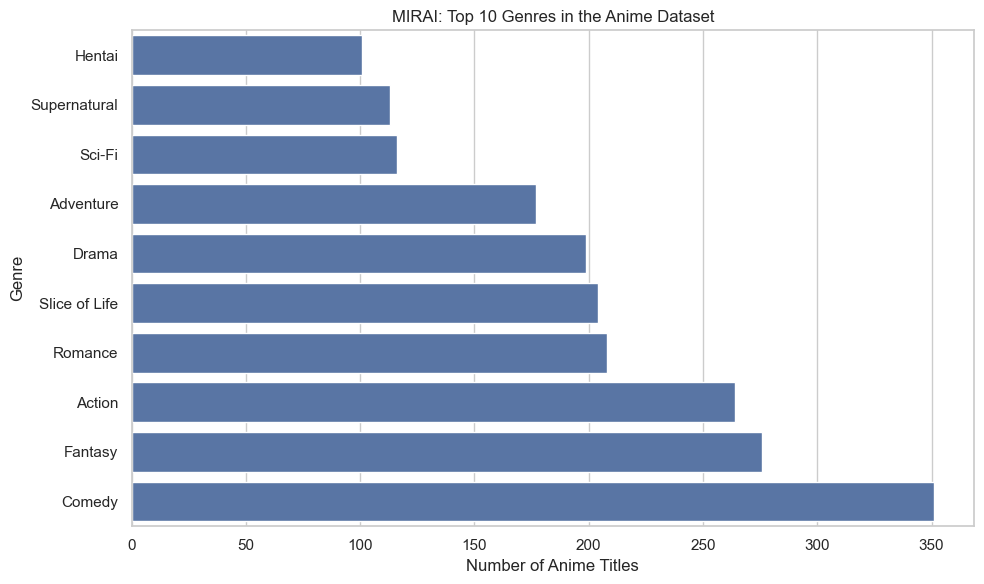

In [12]:
sns.set_theme(style="whitegrid")

# Top 10 genres by number of titles
top_genres = genre_summary.head(10).sort_values("title_count")

plt.figure(figsize=(10, 6))
sns.barplot(
    x=top_genres["title_count"],
    y=top_genres.index
)
plt.title("MIRAI: Top 10 Genres in the Anime Dataset")
plt.xlabel("Number of Anime Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

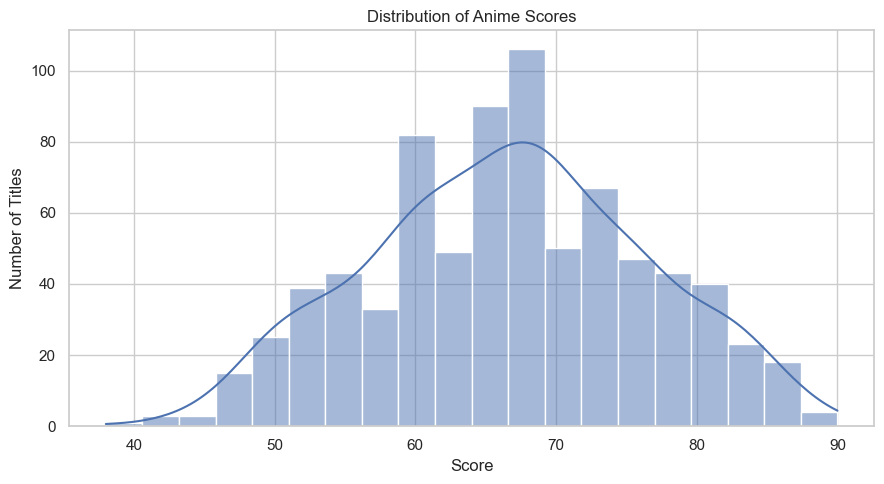

In [13]:
# Distribution of anime scores
plt.figure(figsize=(9, 5))

sns.histplot(
    df_clean["score"].dropna(),
    bins=20,
    kde=True
)

plt.title("Distribution of Anime Scores")
plt.xlabel("Score")
plt.ylabel("Number of Titles")
plt.tight_layout()
plt.show()

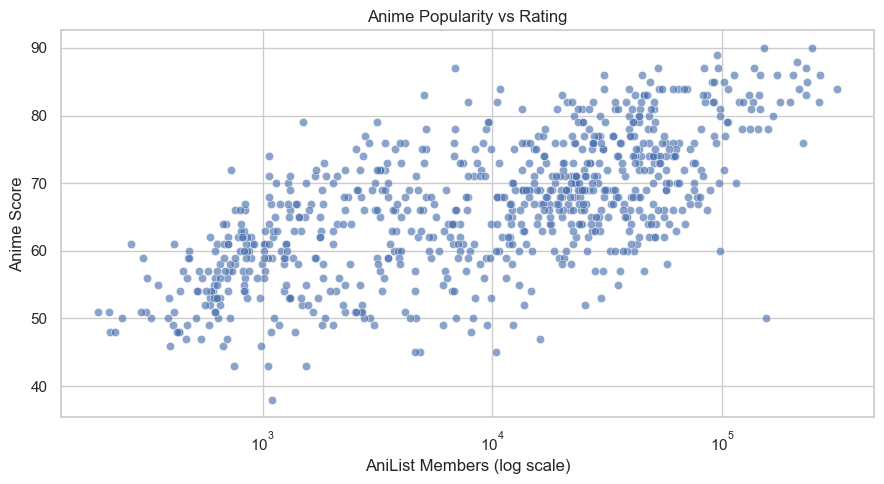

In [14]:
# Popularity vs score
plot_df = df_clean.dropna(
    subset=["members", "score"]
).copy()

plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_df,
    x="members",
    y="score",
    alpha=0.65
)

plt.xscale("log")
plt.title("Anime Popularity vs Rating")
plt.xlabel("AniList Members (log scale)")
plt.ylabel("Anime Score")
plt.tight_layout()
plt.show()

In [15]:
# Save the cleaned anime catalog
df_clean.to_csv(
    "mirai_anime_cleaned.csv",
    index=False
)

# Save genre-level analysis
genre_df.to_csv(
    "mirai_genre_data.csv",
    index=False
)

genre_summary.to_csv(
    "mirai_genre_summary.csv"
)

print("Preprocessing completed successfully!")
print("Saved files:")
print("1. mirai_anime_cleaned.csv")
print("2. mirai_genre_data.csv")
print("3. mirai_genre_summary.csv")
print("Final dataset shape:", df_clean.shape)

Preprocessing completed successfully!
Saved files:
1. mirai_anime_cleaned.csv
2. mirai_genre_data.csv
3. mirai_genre_summary.csv
Final dataset shape: (931, 75)


In [16]:
import os
print(os.getcwd())
print(os.listdir())

C:\Users\user\primecode
['.git', '.ipynb_checkpoints', '.virtual_documents', 'anaconda_projects', 'anime.csv', 'anime_data_table.csv', 'IRIS.csv', 'mirai_anime_cleaned.csv', 'mirai_genre_data.csv', 'mirai_genre_summary.csv', 'placement.csv', 'PlacementDS.ipynb', 'rating.csv', 'README.md', 'Titanic-Dataset.csv', 'Titanic_train.csv', 'Untitled.ipynb', 'Untitled1.ipynb', 'Untitled2.ipynb']
